In [3]:
# ============================================================
# STAGE 6 - CELL 1: Imports and Setup
# ============================================================

import numpy as np
import pandas as pd
import xgboost as xgb
import shap
import matplotlib.pyplot as plt
import joblib
import os
import warnings
warnings.filterwarnings('ignore')

# Reuse the exact same path structure as Stages 1-5
PROJECT_ROOT = "C:/Users/Mahir/Desktop/Solar_Energy_Forecasting_Project"
RESULTS_DIR  = os.path.join(PROJECT_ROOT, "results")
MODELS_DIR   = os.path.join(PROJECT_ROOT, "models")
PLOTS_DIR    = os.path.join(PROJECT_ROOT, "plots")

# Plot styling — matching your Stage 5 conventions
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size']      = 11

shap.initjs()

print("="*55)
print("STAGE 6: SHAP EXPLAINABILITY ANALYSIS")
print("="*55)

STAGE 6: SHAP EXPLAINABILITY ANALYSIS


In [4]:
# ============================================================
# STAGE 6 - CELL 2: Load XGBoost Models and Meta-Features
# ============================================================

print("Loading trained XGBoost models...")

xgb_kano  = joblib.load(os.path.join(MODELS_DIR, 'xgb_kano.pkl'))
xgb_maid  = joblib.load(os.path.join(MODELS_DIR, 'xgb_maid.pkl'))
xgb_abuja = joblib.load(os.path.join(MODELS_DIR, 'xgb_abuja.pkl'))

print("Loading test meta-features (SHAP input matrices)...")

meta_test_kano  = np.load(os.path.join(RESULTS_DIR, 'meta_test_kano.npy'))
meta_test_maid  = np.load(os.path.join(RESULTS_DIR, 'meta_test_maid.npy'))
meta_test_abuja = np.load(os.path.join(RESULTS_DIR, 'meta_test_abuja.npy'))

print("\n" + "="*55)
print("ALL MODELS AND META-FEATURES LOADED")
print("="*55)
print(f"Kano  meta_test shape : {meta_test_kano.shape}")
print(f"Maiduguri meta_test shape: {meta_test_maid.shape}")
print(f"Abuja meta_test shape : {meta_test_abuja.shape}")

Loading trained XGBoost models...
Loading test meta-features (SHAP input matrices)...

ALL MODELS AND META-FEATURES LOADED
Kano  meta_test shape : (8736, 18)
Maiduguri meta_test shape: (8736, 18)
Abuja meta_test shape : (8736, 18)


In [5]:
# ============================================================
# STAGE 6 - CELL 3: Define Feature Names for SHAP
# ============================================================

# Exact order from Stage 3 INPUT_FEATURES, since meta-features
# are built from X_sequences[:, -1, :] which preserves that order.
# Feature 18 is appended in Stage 5 as the CNN-biLSTM prediction.

FEATURE_NAMES = [
    'GHI', 'DHI', 'Clearness',
    'Temperature', 'Humidity', 'WindSpeed',
    'Hour_sin', 'Hour_cos',
    'Month_sin', 'Month_cos',
    'DayOfYear_sin', 'DayOfYear_cos',
    'Season_encoded', 'Is_Daytime',
    'PV_Power_Lag1', 'PV_Power_Lag24', 'GHI_Lag1',
    'CNN_Prediction'    # 18th feature — added in Stage 5
]

print(f"Number of features defined: {len(FEATURE_NAMES)}")

assert len(FEATURE_NAMES) == meta_test_kano.shape[1], \
    "Mismatch between FEATURE_NAMES and meta_test column count!"

print("✅ Feature names verified against meta_test_kano shape")

Number of features defined: 18
✅ Feature names verified against meta_test_kano shape


In [6]:
# ============================================================
# STAGE 6 - CELL 4: Build SHAP TreeExplainers
# ============================================================

# TreeExplainer computes EXACT Shapley values for tree-based
# models by walking the actual tree structure (Lundberg et al.,
# 2018 — "Tree SHAP" algorithm), rather than approximating via
# sampling like KernelExplainer. This is both faster and exact
# for XGBoost, unlike the model-agnostic alternatives.

print("Building TreeExplainers...")

explainer_kano  = shap.TreeExplainer(xgb_kano)
explainer_maid  = shap.TreeExplainer(xgb_maid)
explainer_abuja = shap.TreeExplainer(xgb_abuja)

print("✅ TreeExplainer built for Kano")
print("✅ TreeExplainer built for Maiduguri")
print("✅ TreeExplainer built for Abuja")

Building TreeExplainers...
✅ TreeExplainer built for Kano
✅ TreeExplainer built for Maiduguri
✅ TreeExplainer built for Abuja


In [7]:
# ============================================================
# STAGE 6 - CELL 5: Compute SHAP Values
# ============================================================

print("Computing SHAP values (this may take a moment)...\n")

shap_values_kano  = explainer_kano.shap_values(meta_test_kano)
shap_values_maid  = explainer_maid.shap_values(meta_test_maid)
shap_values_abuja = explainer_abuja.shap_values(meta_test_abuja)

print(f"Kano  SHAP values shape : {shap_values_kano.shape}")
print(f"Maiduguri SHAP values shape: {shap_values_maid.shape}")
print(f"Abuja SHAP values shape: {shap_values_abuja.shape}")

print("\n✅ SHAP values computed for all three cities")

Computing SHAP values (this may take a moment)...

Kano  SHAP values shape : (8736, 18)
Maiduguri SHAP values shape: (8736, 18)
Abuja SHAP values shape: (8736, 18)

✅ SHAP values computed for all three cities


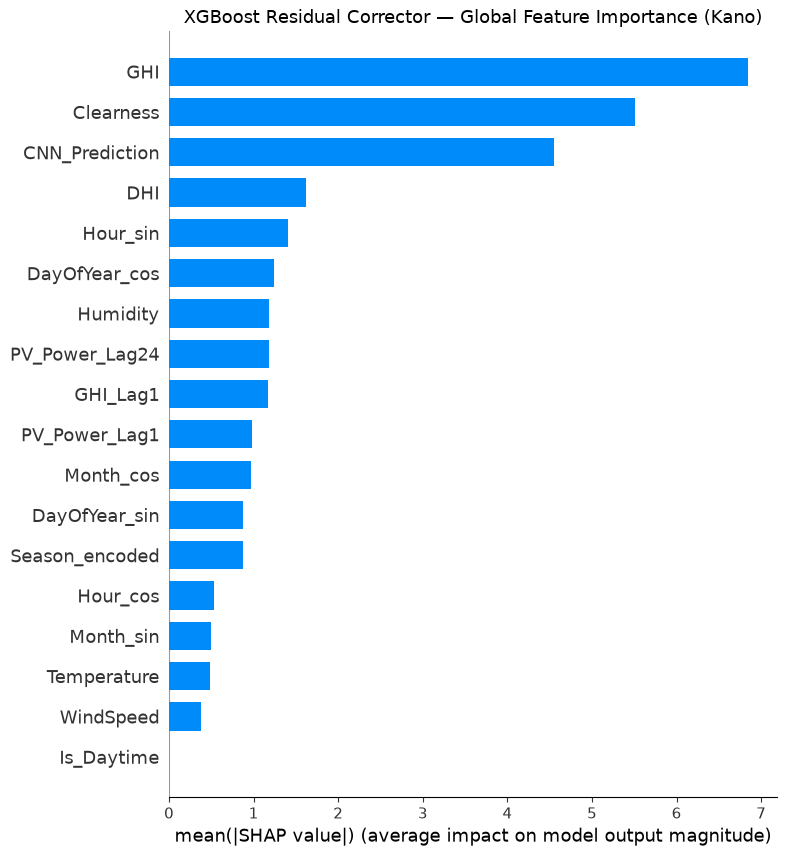

✅ Saved: shap_bar_kano.png



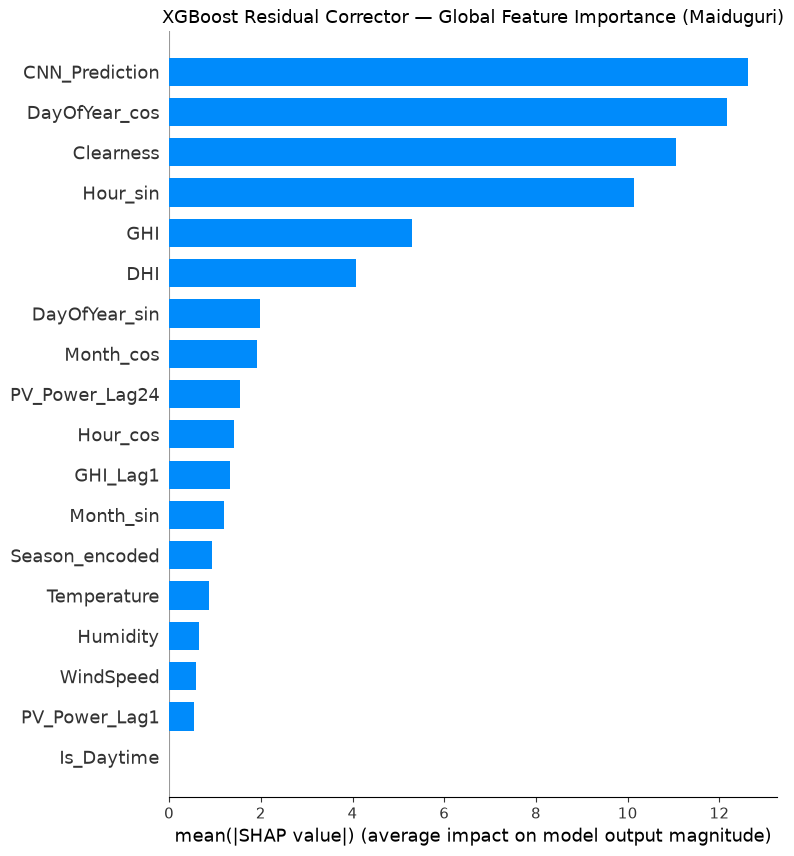

✅ Saved: shap_bar_maiduguri.png



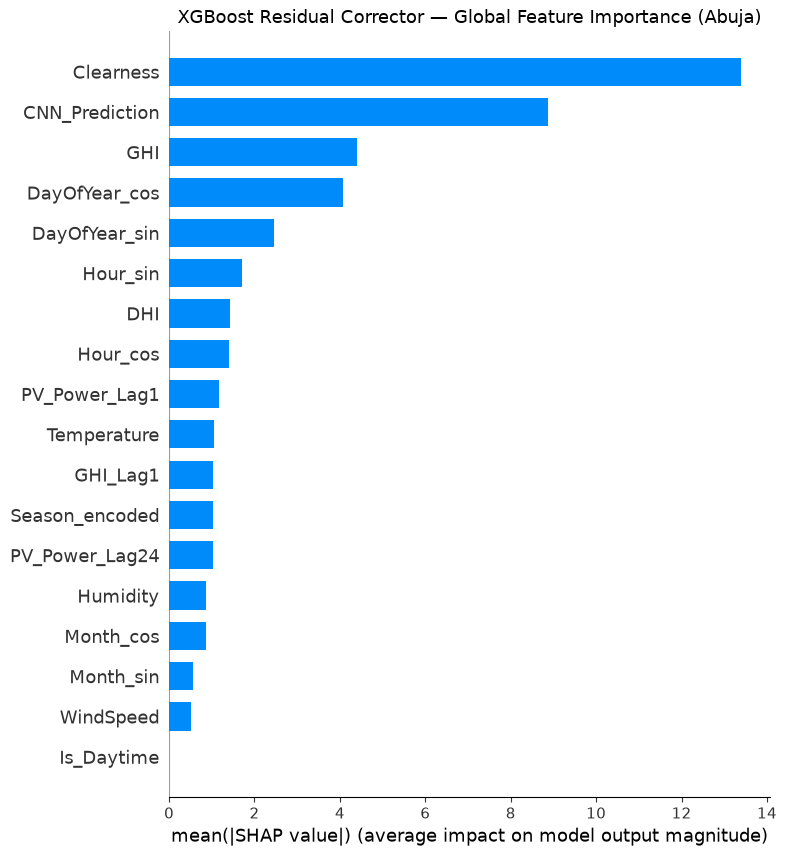

✅ Saved: shap_bar_abuja.png



In [8]:
# ============================================================
# STAGE 6 - CELL 6: Global Feature Importance (Bar Plots)
# ============================================================

city_data = [
    ('Kano',      shap_values_kano,  meta_test_kano),
    ('Maiduguri', shap_values_maid,  meta_test_maid),
    ('Abuja',     shap_values_abuja, meta_test_abuja),
]

for city, sv, X in city_data:
    plt.figure()
    shap.summary_plot(
        sv, X,
        feature_names=FEATURE_NAMES,
        plot_type="bar",
        show=False
    )
    plt.title(f"XGBoost Residual Corrector — Global Feature Importance ({city})")
    plt.tight_layout()
    plt.savefig(
        os.path.join(PLOTS_DIR, f"shap_bar_{city.lower()}.png"),
        dpi=300, bbox_inches="tight"
    )
    plt.show()
    print(f"✅ Saved: shap_bar_{city.lower()}.png\n")

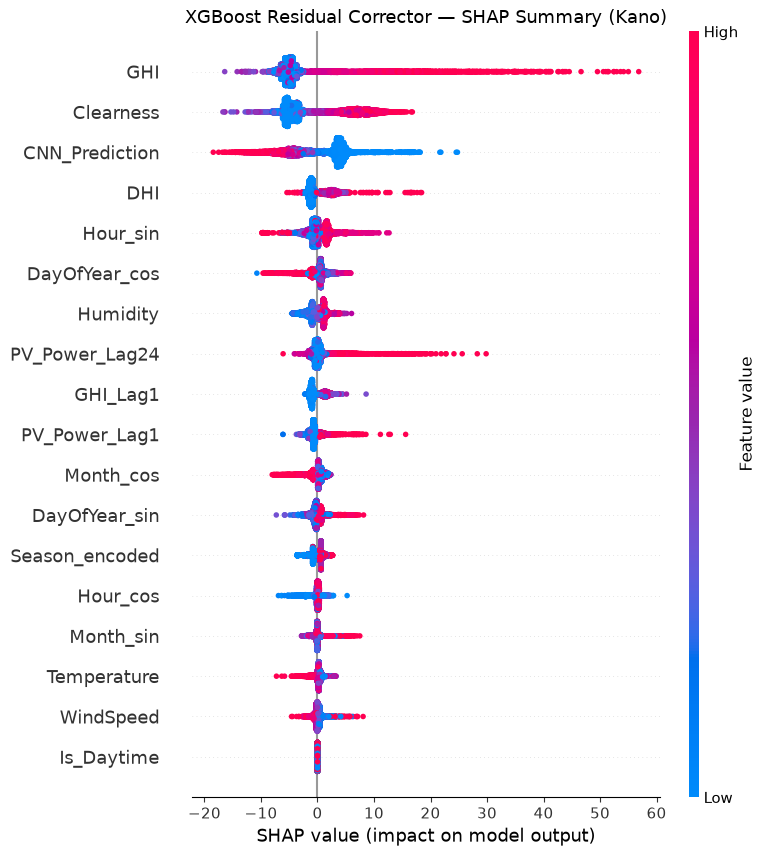

✅ Saved: shap_beeswarm_kano.png



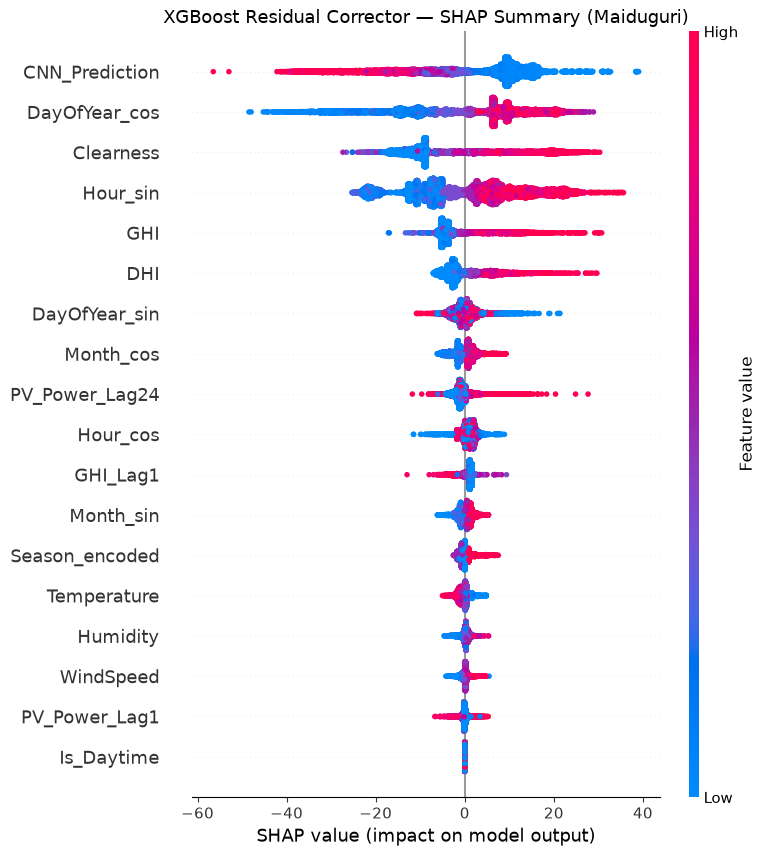

✅ Saved: shap_beeswarm_maiduguri.png



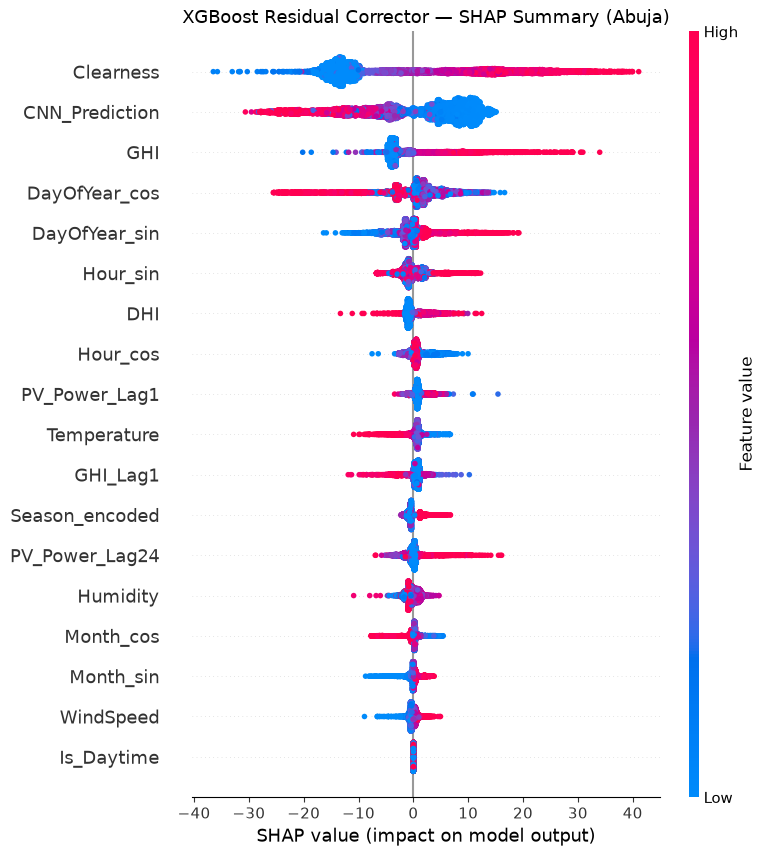

✅ Saved: shap_beeswarm_abuja.png



In [9]:
# ============================================================
# STAGE 6 - CELL 7: SHAP Beeswarm Plots (Importance + Direction)
# ============================================================

for city, sv, X in city_data:
    plt.figure()
    shap.summary_plot(
        sv, X,
        feature_names=FEATURE_NAMES,
        show=False
        # no plot_type → defaults to beeswarm/dot plot
    )
    plt.title(f"XGBoost Residual Corrector — SHAP Summary ({city})")
    plt.tight_layout()
    plt.savefig(
        os.path.join(PLOTS_DIR, f"shap_beeswarm_{city.lower()}.png"),
        dpi=300, bbox_inches="tight"
    )
    plt.show()
    print(f"✅ Saved: shap_beeswarm_{city.lower()}.png\n")

<Figure size 1000x600 with 0 Axes>

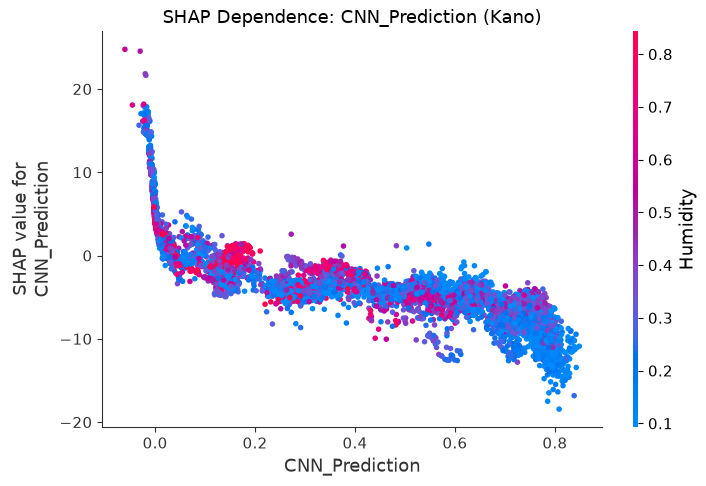

✅ Saved: shap_dep_cnn_prediction_kano.png


<Figure size 1000x600 with 0 Axes>

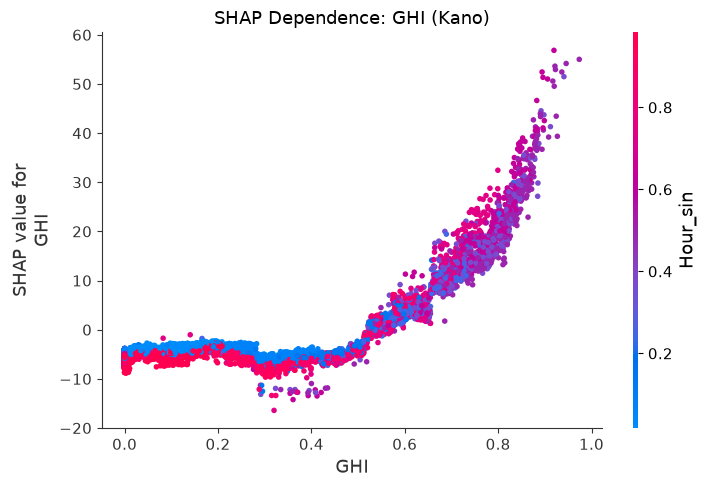

✅ Saved: shap_dep_ghi_kano.png


<Figure size 1000x600 with 0 Axes>

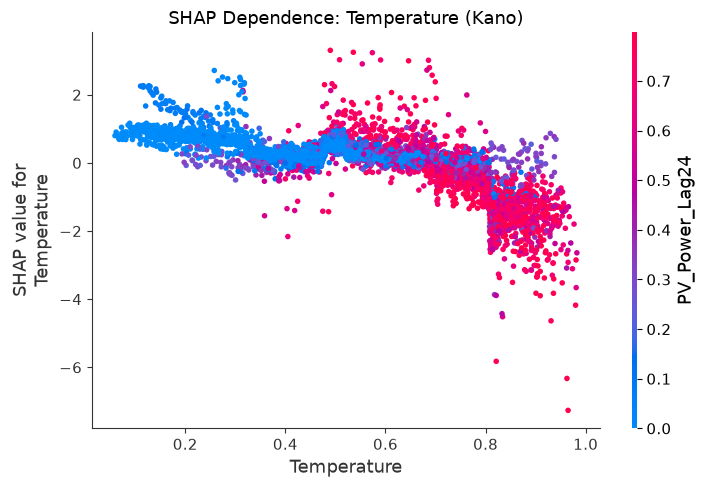

✅ Saved: shap_dep_temperature_kano.png



<Figure size 1000x600 with 0 Axes>

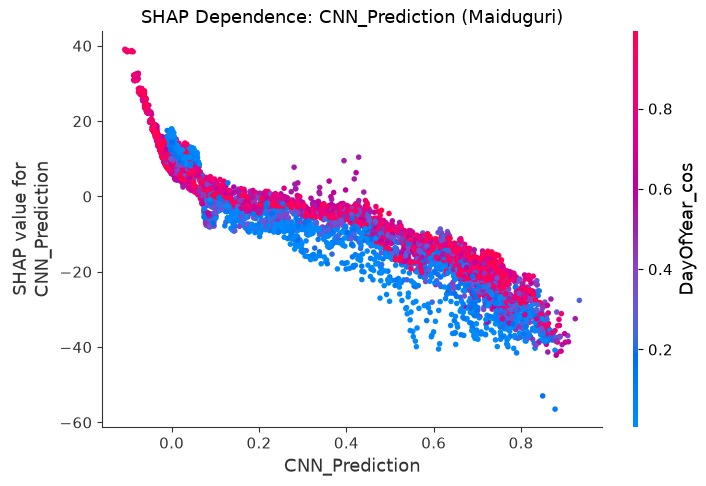

✅ Saved: shap_dep_cnn_prediction_maiduguri.png


<Figure size 1000x600 with 0 Axes>

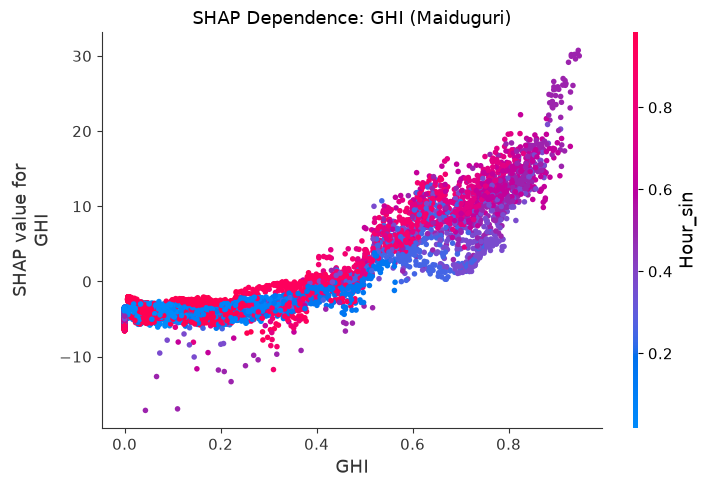

✅ Saved: shap_dep_ghi_maiduguri.png


<Figure size 1000x600 with 0 Axes>

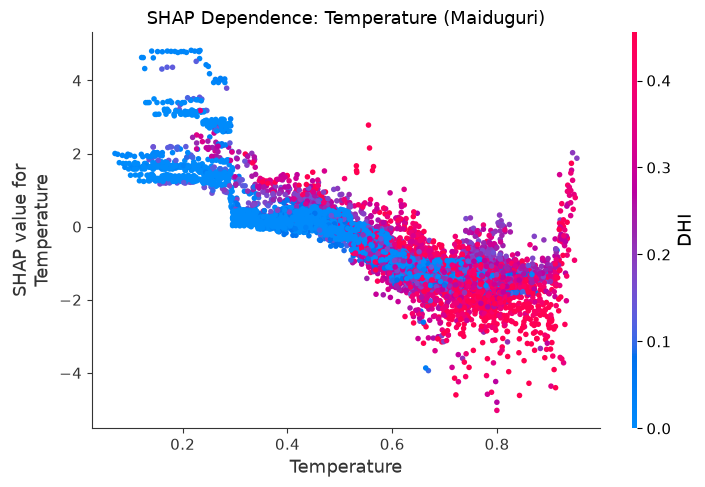

✅ Saved: shap_dep_temperature_maiduguri.png



<Figure size 1000x600 with 0 Axes>

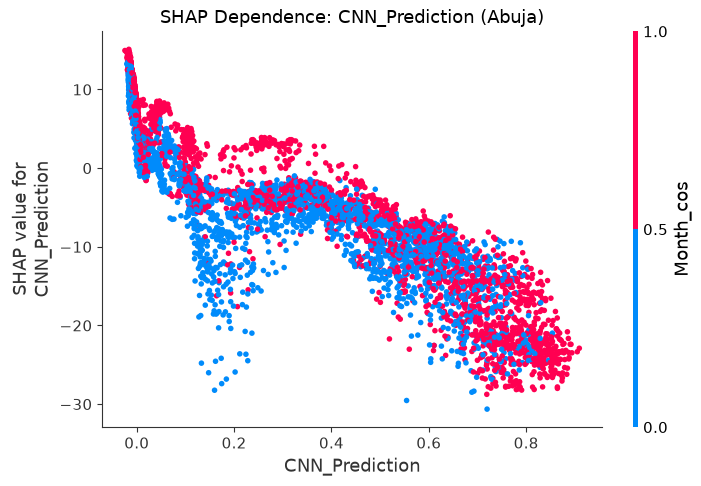

✅ Saved: shap_dep_cnn_prediction_abuja.png


<Figure size 1000x600 with 0 Axes>

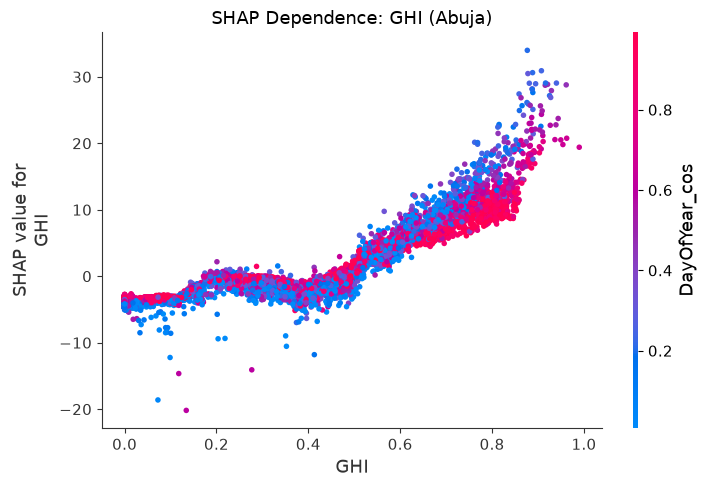

✅ Saved: shap_dep_ghi_abuja.png


<Figure size 1000x600 with 0 Axes>

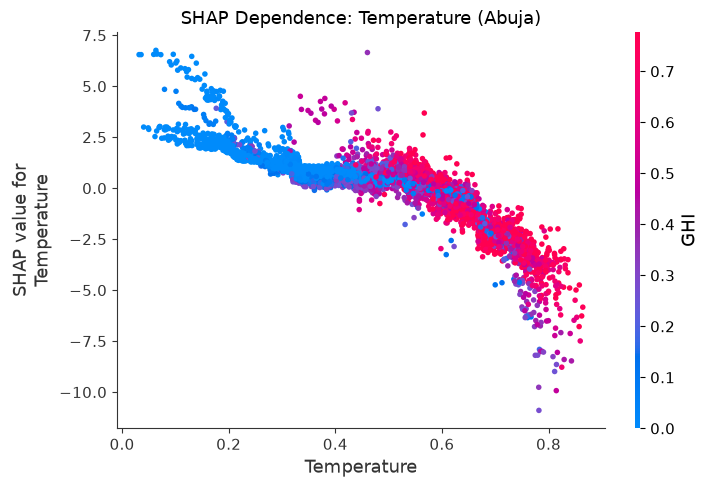

✅ Saved: shap_dep_temperature_abuja.png



In [10]:
# ============================================================
# STAGE 6 - CELL 8: SHAP Dependence Plots
# ============================================================

# Dependence plots show how SHAP values for ONE feature change
# as that feature's value changes — and SHAP automatically picks
# a second feature (by strongest interaction) to colour the dots by.
# This reveals INTERACTIONS, not just individual feature effects —
# critical for showing how your hybrid architecture's two stages
# actually talk to each other.

dependence_features = ['CNN_Prediction', 'GHI', 'Temperature']

for city, sv, X in city_data:
    for feat in dependence_features:
        plt.figure()
        shap.dependence_plot(
            feat, sv, X,
            feature_names=FEATURE_NAMES,
            show=False
        )
        plt.title(f"SHAP Dependence: {feat} ({city})")
        plt.tight_layout()
        plt.savefig(
            os.path.join(PLOTS_DIR, f"shap_dep_{feat.lower()}_{city.lower()}.png"),
            dpi=300, bbox_inches="tight"
        )
        plt.show()
        print(f"✅ Saved: shap_dep_{feat.lower()}_{city.lower()}.png")
    print()

In [14]:
# Optional: inverse-transform selected features back to physical units
# for more readable dependence plot axes (uses Stage 3's saved scalers)

feat_scaler_kano  = joblib.load(os.path.join(MODELS_DIR, 'feat_scaler_kano.pkl'))
feat_scaler_maid  = joblib.load(os.path.join(MODELS_DIR, 'feat_scaler_maid.pkl'))
feat_scaler_abuja = joblib.load(os.path.join(MODELS_DIR, 'feat_scaler_abuja.pkl'))

# Reconstruct a dummy 17-column array, inverse-transform, then re-extract
# the one column you care about (scaler expects all 17 columns at once)
def inverse_single_feature(X_18col, scaler, feature_idx, n_features=17):
    dummy = X_18col[:, :n_features].copy()   # drop the 18th (CNN_Prediction) column
    return scaler.inverse_transform(dummy)[:, feature_idx]

# Example: get Kano's real temperature values (index 3 in FEATURE_NAMES)
temp_idx = FEATURE_NAMES.index('Temperature')
real_temp_kano = inverse_single_feature(meta_test_kano, feat_scaler_kano, temp_idx)
print(f"Kano real temperature range: {real_temp_kano.min():.1f}°C to {real_temp_kano.max():.1f}°C")

Kano real temperature range: 9.9°C to 42.4°C


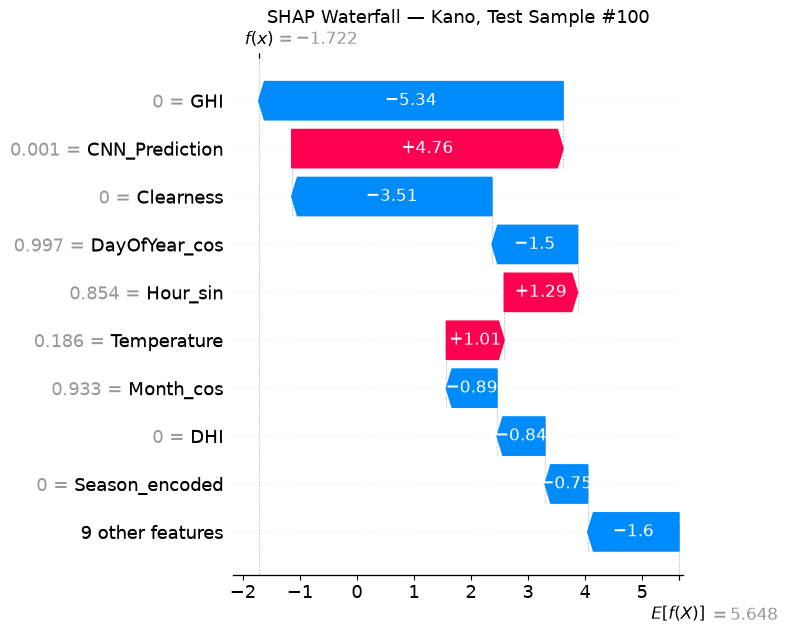

✅ Saved: shap_waterfall_kano_sample100.png



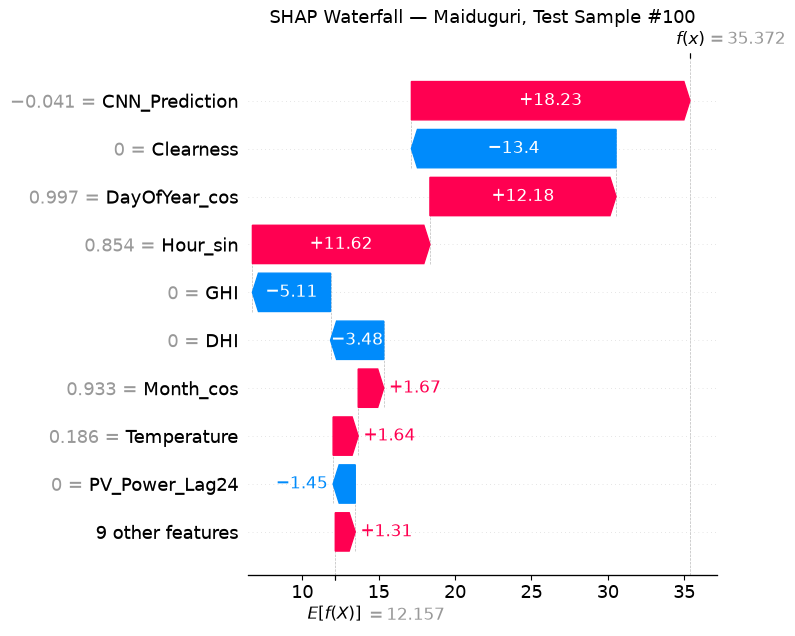

✅ Saved: shap_waterfall_maiduguri_sample100.png



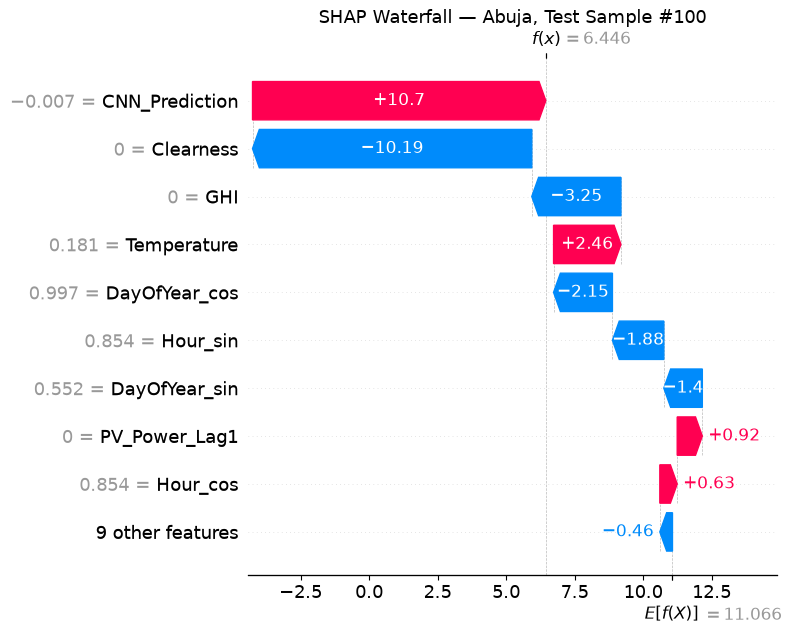

✅ Saved: shap_waterfall_abuja_sample100.png



In [15]:
# ============================================================
# STAGE 6 - CELL 9: Waterfall Plot for a Single Prediction
# ============================================================

# A waterfall plot answers a very specific, defense-friendly question:
# "For THIS ONE hour, why did the model predict what it predicted?"
# This is the plot to have ready if your supervisor asks
# "can you show me a concrete example, not just averages?"

def plot_waterfall(explainer, sv, X, city, sample_idx=0):
    """
    Plots a SHAP waterfall for a single test-set sample.
    sample_idx: row index within the test set to explain.
    """
    explanation = shap.Explanation(
        values=sv[sample_idx],
        base_values=explainer.expected_value,
        data=X[sample_idx],
        feature_names=FEATURE_NAMES
    )
    plt.figure()
    shap.plots.waterfall(explanation, show=False)
    plt.title(f"SHAP Waterfall — {city}, Test Sample #{sample_idx}")
    plt.tight_layout()
    plt.savefig(
        os.path.join(PLOTS_DIR, f"shap_waterfall_{city.lower()}_sample{sample_idx}.png"),
        dpi=300, bbox_inches="tight"
    )
    plt.show()
    print(f"✅ Saved: shap_waterfall_{city.lower()}_sample{sample_idx}.png\n")


# Pick a sample from each city — index 100 avoids the very first
# few rows, which can sometimes be edge cases (e.g. night hours)
plot_waterfall(explainer_kano,  shap_values_kano,  meta_test_kano,  'Kano',      sample_idx=100)
plot_waterfall(explainer_maid,  shap_values_maid,  meta_test_maid,  'Maiduguri', sample_idx=100)
plot_waterfall(explainer_abuja, shap_values_abuja, meta_test_abuja, 'Abuja',     sample_idx=100)

In [16]:
# ============================================================
# STAGE 6 - CELL 10: SHAP Feature Importance Summary Table
# ============================================================

def build_importance_table(sv, city):
    """
    Builds a ranked table of mean |SHAP value| per feature —
    a clean numeric summary to complement the visual plots,
    suitable for a thesis appendix table.
    """
    mean_abs_shap = np.abs(sv).mean(axis=0)
    df = pd.DataFrame({
        'Feature': FEATURE_NAMES,
        'Mean_Abs_SHAP': mean_abs_shap,
        'City': city
    }).sort_values('Mean_Abs_SHAP', ascending=False).reset_index(drop=True)
    df.index += 1  # 1-indexed rank for readability
    return df

table_kano  = build_importance_table(shap_values_kano,  'Kano')
table_maid  = build_importance_table(shap_values_maid,  'Maiduguri')
table_abuja = build_importance_table(shap_values_abuja, 'Abuja')

# Combine into one long-format table for easy comparison across cities
summary_table = pd.concat([table_kano, table_maid, table_abuja])
summary_table.to_csv(os.path.join(RESULTS_DIR, 'shap_importance_summary.csv'), index=True)

print("="*55)
print("SHAP FEATURE IMPORTANCE SUMMARY (Top 5 per city)")
print("="*55)
for city, table in [('Kano', table_kano), ('Maiduguri', table_maid), ('Abuja', table_abuja)]:
    print(f"\n{city}:")
    print(table.head(5).to_string(index=True))

print(f"\n✅ Full table saved to: shap_importance_summary.csv")

SHAP FEATURE IMPORTANCE SUMMARY (Top 5 per city)

Kano:
          Feature  Mean_Abs_SHAP  City
1             GHI       6.843788  Kano
2       Clearness       5.502697  Kano
3  CNN_Prediction       4.546416  Kano
4             DHI       1.620123  Kano
5        Hour_sin       1.407342  Kano

Maiduguri:
          Feature  Mean_Abs_SHAP       City
1  CNN_Prediction      12.624112  Maiduguri
2   DayOfYear_cos      12.175186  Maiduguri
3       Clearness      11.050570  Maiduguri
4        Hour_sin      10.140349  Maiduguri
5             GHI       5.298073  Maiduguri

Abuja:
          Feature  Mean_Abs_SHAP   City
1       Clearness      13.398918  Abuja
2  CNN_Prediction       8.866255  Abuja
3             GHI       4.405874  Abuja
4   DayOfYear_cos       4.077417  Abuja
5   DayOfYear_sin       2.467262  Abuja

✅ Full table saved to: shap_importance_summary.csv


In [17]:
# ============================================================
# STAGE 6 - CELL 11: Stage 6 Completion Summary
# ============================================================

print("="*60)
print("STAGE 6 COMPLETE — SHAP EXPLAINABILITY ANALYSIS")
print("="*60)
print()
print("✅ TreeExplainers built for all three XGBoost residual correctors")
print()
print("✅ Global feature importance computed")
print("   (Bar plots + beeswarm plots, per city)")
print()
print("✅ Feature interactions explored")
print("   (Dependence plots: CNN_Prediction, GHI, Temperature)")
print()
print("✅ Local (single-prediction) explanations generated")
print("   (Waterfall plots, one representative hour per city)")
print()
print("✅ Numeric importance summary saved")
print("   (shap_importance_summary.csv)")
print()
print("NEXT → Stage 7: Final Reporting / Thesis Writing")
print("="*60)

STAGE 6 COMPLETE — SHAP EXPLAINABILITY ANALYSIS

✅ TreeExplainers built for all three XGBoost residual correctors

✅ Global feature importance computed
   (Bar plots + beeswarm plots, per city)

✅ Feature interactions explored
   (Dependence plots: CNN_Prediction, GHI, Temperature)

✅ Local (single-prediction) explanations generated
   (Waterfall plots, one representative hour per city)

✅ Numeric importance summary saved
   (shap_importance_summary.csv)

NEXT → Stage 7: Final Reporting / Thesis Writing
